# 33 · Where does the result hold across garments?

Break down the fixed Fashion-MNIST comparison by clothing category and distractor composition. The group-level primary analysis stays in Notebook 32. Category breakdowns diagnose heterogeneity among the sampled garments.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage8 import BASELINES,FROZEN,VIEWS,contrast
from observables.stage9 import load_fashion,observations,cross_dataset_contrast
from observables.stage6 import CONDITIONS
OUT=ROOT/'results'/'stage9'
MNIST=ROOT/'results'/'stage8'
CATEGORIES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

method,aligned local Q,aligned Q magnitude,aligned structure tensor,aligned ZNCC
T-shirt/top,56.5,42.4,54.4,59.6
Trouser,77.6,64.3,82.0,65.9
Pullover,40.4,26.8,41.1,27.3
Dress,32.0,28.4,28.6,48.4
Coat,33.3,25.5,34.6,38.5
Sandal,45.8,31.2,46.1,19.0
Shirt,24.0,21.9,24.0,23.2
Sneaker,81.2,58.1,79.4,82.6
Bag,60.4,46.9,58.9,60.9
Ankle boot,82.8,63.8,84.4,81.2


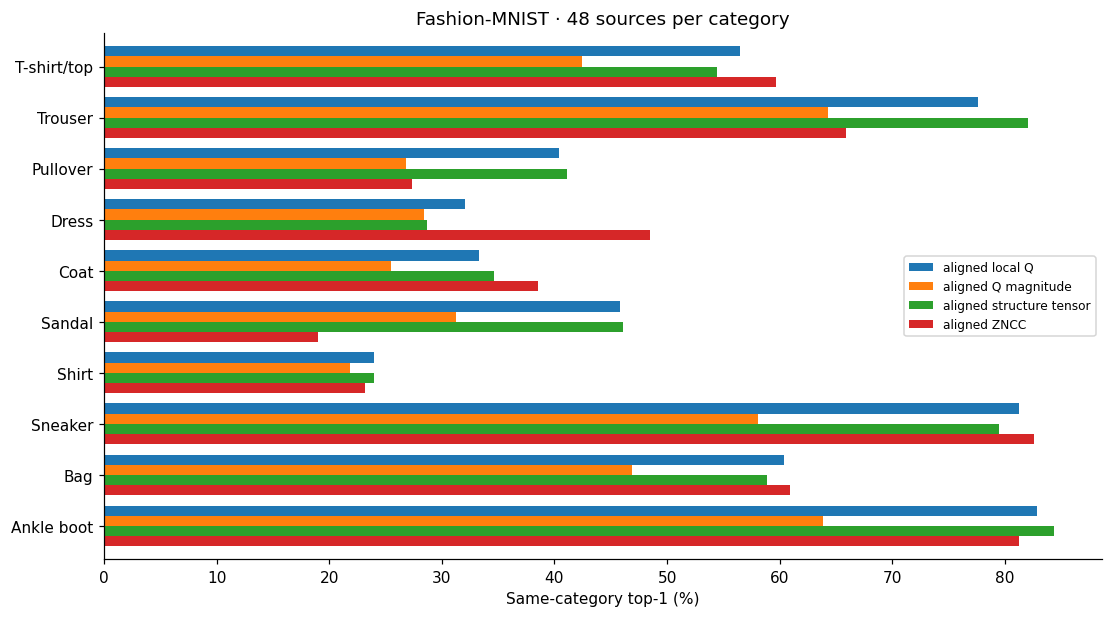

In [3]:
all_views=pd.read_csv(OUT/'decisions.csv.gz')
membership=pd.read_csv(OUT/'membership.csv')
full=all_views.query("gallery_type=='full'").merge(membership,on=['panel','gallery','source'],validate='many_to_one')
methods=['aligned local Q','aligned Q magnitude','aligned structure tensor','aligned ZNCC']
z=full[full.method.isin(methods)].groupby(['label','method'])['class'].mean().unstack()[methods]
z.index=CATEGORIES
display((z*100).round(1))
z.to_csv(OUT/'class_by_category.csv')
fig,ax=plt.subplots(figsize=(10,5.5))
(z*100).plot.barh(ax=ax,width=.8)
ax.set(xlabel='Same-category top-1 (%)',ylabel='',title='Fashion-MNIST · 48 sources per category')
ax.invert_yaxis();ax.legend(fontsize=8)
show('33_fashion_categories')

## Separate gallery size from visual competition
Within each full gallery, keep all three same-category exemplars and add 16 wrong-category examples. Compare the 16 nearest wrong-category images by coarse clean-pixel distance with a seeded random draw of 16. Every method sees the same subsets. This is the same challenge definition used on MNIST.

In [5]:
summary=pd.read_csv(OUT/'summary.csv')
short=summary.query("gallery_type!='full'").pivot(index='method',columns='gallery_type',values='class')
short=short.loc[[*methods,'ResNet-50 local Q','EfficientNet-B0 cosine']]
short['hard minus random']=short['hard 19']-short['random 19']
display((short*100).round(2));short.to_csv(OUT/'hard_distractor_summary.csv')

gallery_type,hard 19,random 19,hard minus random
method,,,
aligned local Q,54.66,64.40,-9.74
aligned Q magnitude,43.23,53.23,-10.00
aligned structure tensor,54.82,63.96,-9.14
aligned ZNCC,53.20,60.39,-7.19
ResNet-50 local Q,44.92,55.55,-10.62
EfficientNet-B0 cosine,42.55,51.04,-8.49


## Inspect one case in each direction
Choose the first deterministic case where Q succeeds and magnitude fails, and the first case with the reverse outcome. Restrict to strict top-1 success and failure. These examples illustrate disagreements between two search-aware comparisons. Their frequency is measured by the full-panel tables above.

Q alone succeeds: 709 · magnitude alone succeeds: 230


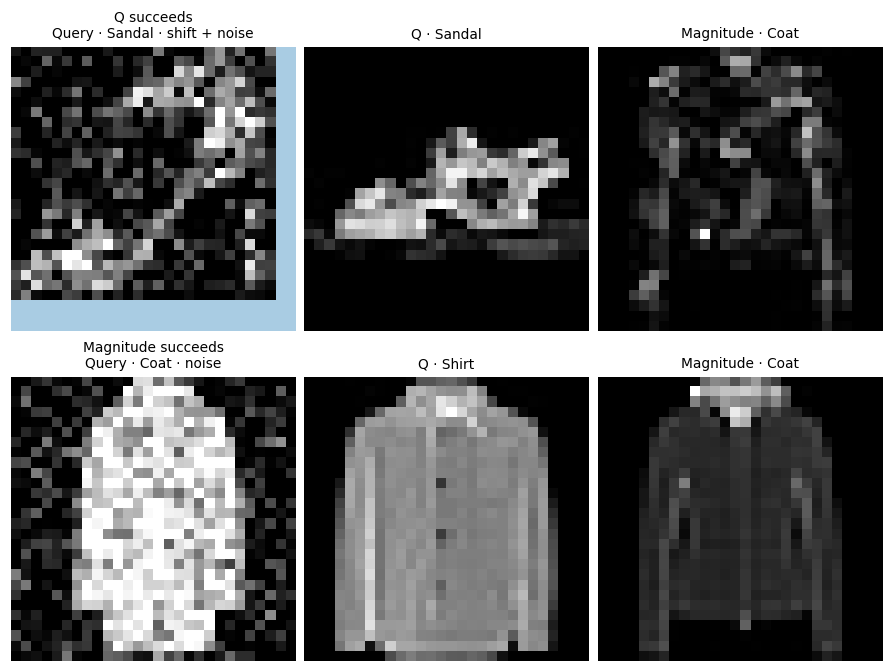

In [7]:
scores=full.pivot(index=['gallery','source','condition'],columns='method',values='class')
qwin=(scores['aligned local Q']==1)&(scores['aligned Q magnitude']==0)
mwin=(scores['aligned local Q']==0)&(scores['aligned Q magnitude']==1)
print('Q alone succeeds:',qwin.sum(),'· magnitude alone succeeds:',mwin.sum())
cases=[(flag[flag].index[0],title) for flag,title in [(qwin,'Q succeeds'),(mwin,'Magnitude succeeds')] if flag.any()]
data=load_fashion()
ex=set(pd.read_csv(OUT/'excluded_test_ids.csv').source)
pairs=pd.read_csv(OUT/'classical_pairs.csv.gz')
fig,axes=plt.subplots(len(cases),3,figsize=(8,3*len(cases)),squeeze=False)
for _,group,ids,images,labels,queries in observations(data,ex):
    for row,(key,title) in enumerate(cases):
        block,source,condition=key
        if block!=group:continue
        position=np.flatnonzero(ids==source).item()
        q=queries[position*len(CONDITIONS)+CONDITIONS.index(condition)]
        p=pairs[(pairs.gallery==block)&(pairs.source==source)&(pairs.condition==condition)&(pairs.candidate!=source)]
        winners=[int(p.loc[p[m].idxmin(),'candidate']) for m in ['aligned local Q','aligned Q magnitude']]
        labels_out=[CATEGORIES[data['y_test'][i]] for i in winners]
        images_out=[np.where(q.valid,q.image,np.nan),*[data['x_test'][i]/255 for i in winners]]
        names=[f'{title}\nQuery · {CATEGORIES[data["y_test"][source]]} · {condition}',
               f'Q · {labels_out[0]}',f'Magnitude · {labels_out[1]}']
        for ax,im,name in zip(axes[row],images_out,names):
            ax.imshow(im,cmap=plt.get_cmap('gray').with_extremes(bad='#a9cce3'),vmin=0,vmax=1)
            ax.set_title(name,fontsize=9);ax.set_axis_off()
show('33_fashion_phase_examples')

The orientation phase can help by retaining the arrangement of garment edges and can hurt when a different legitimate example has a different cut or pose. The category label specifies the target here. Visual resemblance would require a separate human judgment study.